# Учимся работе с данными - от загрузки до моделирования

In [30]:
#YOUR CODE HERE

# Загружаем необходимые библиотеки
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [160]:
# Прочитем файл и сформируем датасет
df = pd.read_csv('data.csv')
df

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,NaN
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,NaN
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,NaN
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,NaN


In [161]:
# Посмотрим на общее количество строк и столбцов
print(f'Размер датасета (строки, столбцы):{df.shape}')

Размер датасета (строки, столбцы):(569, 33)


In [162]:
# Посмотрим информацию по каждому столбцу
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [163]:
# Посмотрим количество уникальных значений в каждом столбце
df.nunique()

id                         569
diagnosis                    2
radius_mean                456
texture_mean               479
perimeter_mean             522
area_mean                  539
smoothness_mean            474
compactness_mean           537
concavity_mean             537
concave points_mean        542
symmetry_mean              432
fractal_dimension_mean     499
radius_se                  540
texture_se                 519
perimeter_se               533
area_se                    528
smoothness_se              547
compactness_se             541
concavity_se               533
concave points_se          507
symmetry_se                498
fractal_dimension_se       545
radius_worst               457
texture_worst              511
perimeter_worst            514
area_worst                 544
smoothness_worst           411
compactness_worst          529
concavity_worst            539
concave points_worst       492
symmetry_worst             500
fractal_dimension_worst    535
Unnamed:

In [164]:
# Посмотрим на статистику числовых признаков
df.describe()

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


#### Краткие выводы:  
* Датасет имеет 33 столбца и 569 строк. 
* Пропусков в данных нет.
* Столбец id содержит 569 уникальных значений, значения очень большие, видимо, идентификатор пациента.  
  Как признак, его использовать нельзя, но на всякий случай сохраню, сделаю его индексом строк.
* Столбец 'Unnamed: 32' не содержит никаких данных, удалю.

In [165]:
# Сделаем 'id' индексом строк. 
df.set_index('id', inplace=True)
df

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
id,,,,,,,,,,,,,,,,,,,,,
842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,NaN
842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,NaN
84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,NaN
84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,NaN
84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,NaN
926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,NaN
926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,NaN


In [166]:
# Удаляем столбец 'Unnamed: 32'
df.drop('Unnamed: 32', axis=1, inplace=True)
df

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
id,,,,,,,,,,,,,,,,,,,,,
842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820


In [167]:
# Есть некоторое несоответствие в названиях столбцов, приведём всё к одному виду.
df = df.rename(
    columns={
        "fractal_dimension_mean": "fractal dimension_mean",
        "fractal_dimension_se": "fractal dimension_se",
        "fractal_dimension_worst": "fractal dimension_worst",
    }
)
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 569 entries, 842302 to 92751
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis                569 non-null    object 
 1   radius_mean              569 non-null    float64
 2   texture_mean             569 non-null    float64
 3   perimeter_mean           569 non-null    float64
 4   area_mean                569 non-null    float64
 5   smoothness_mean          569 non-null    float64
 6   compactness_mean         569 non-null    float64
 7   concavity_mean           569 non-null    float64
 8   concave points_mean      569 non-null    float64
 9   symmetry_mean            569 non-null    float64
 10  fractal dimension_mean   569 non-null    float64
 11  radius_se                569 non-null    float64
 12  texture_se               569 non-null    float64
 13  perimeter_se             569 non-null    float64
 14  area_se                 

In [168]:
# Проверим датасет на дисбаланс классов
# В абсолютных значениях
print(f'Количество по классам {df['diagnosis'].value_counts()}')

# В процентах
print(f'\nДоля каждого класса {df['diagnosis'].value_counts(normalize=True) * 100}')

Количество по классам diagnosis
B    357
M    212
Name: count, dtype: int64

Доля каждого класса diagnosis
B    62.741652
M    37.258348
Name: proportion, dtype: float64


#### Краткий вывод:  
* В датасете отмечается значительный дисбаланс классов. 

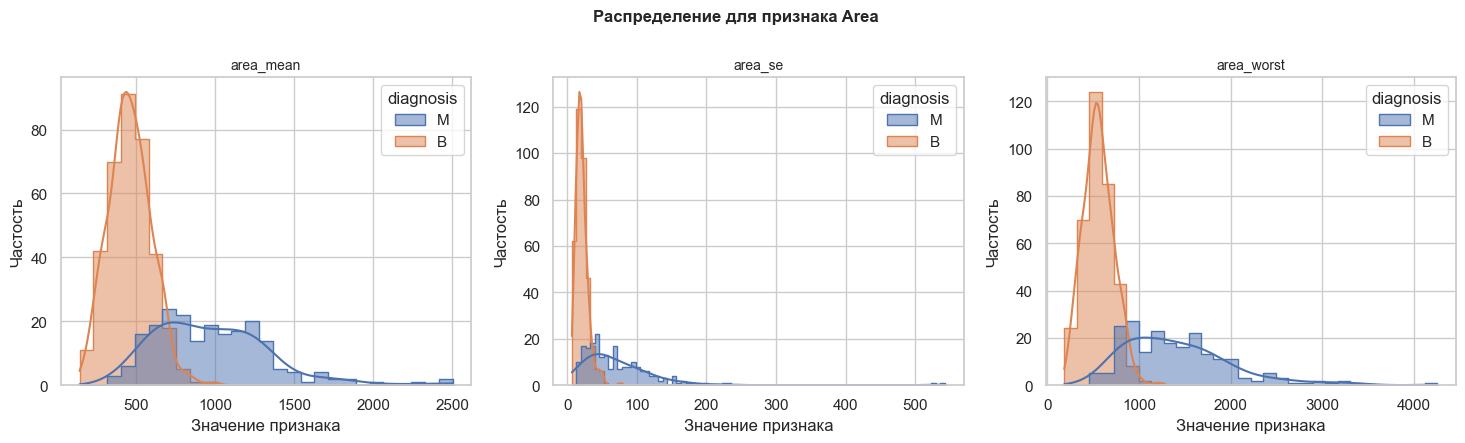

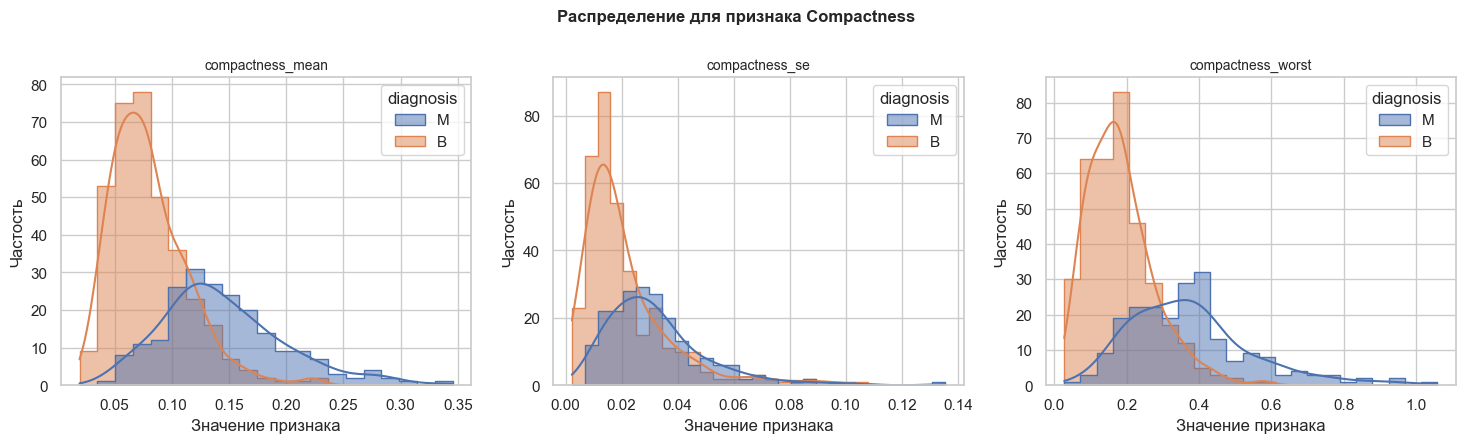

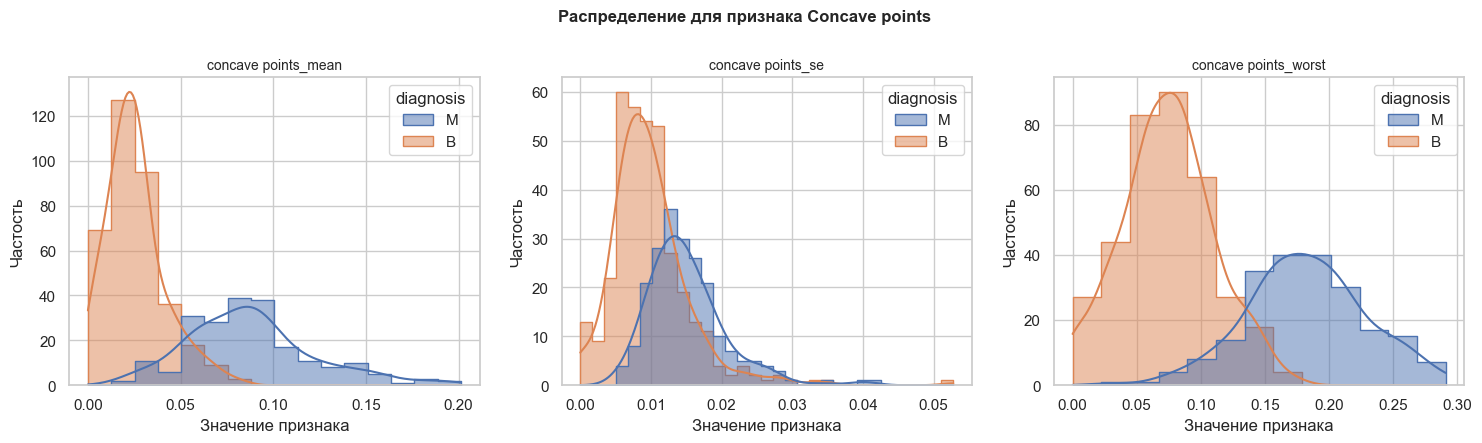

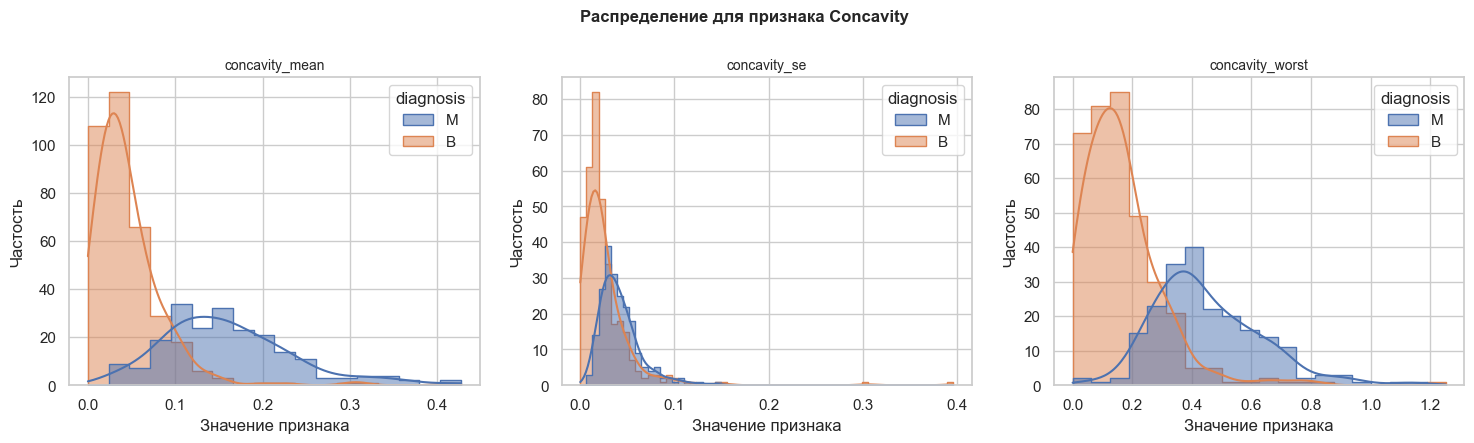

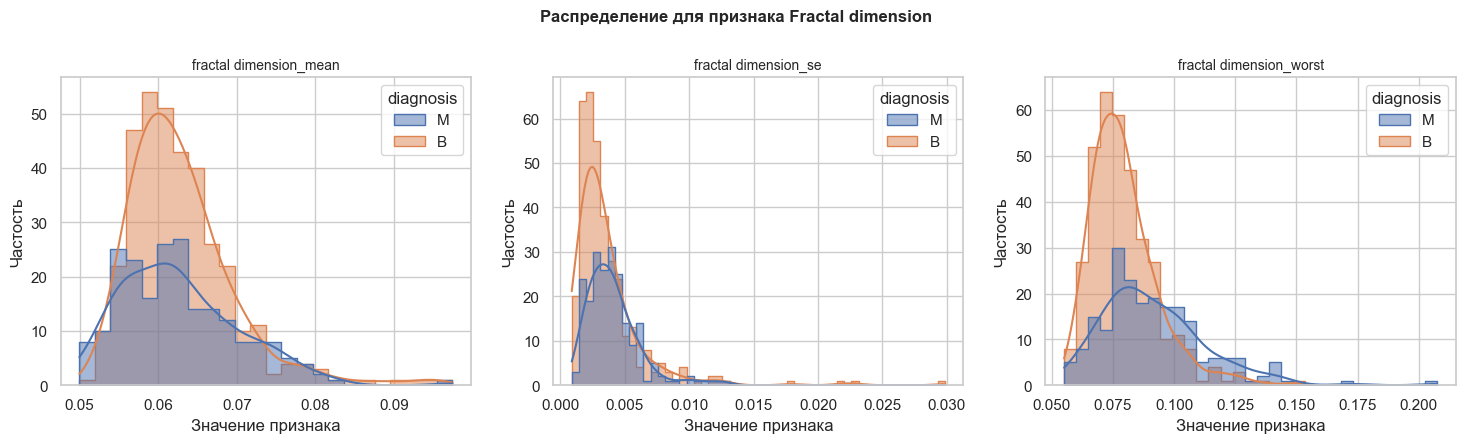

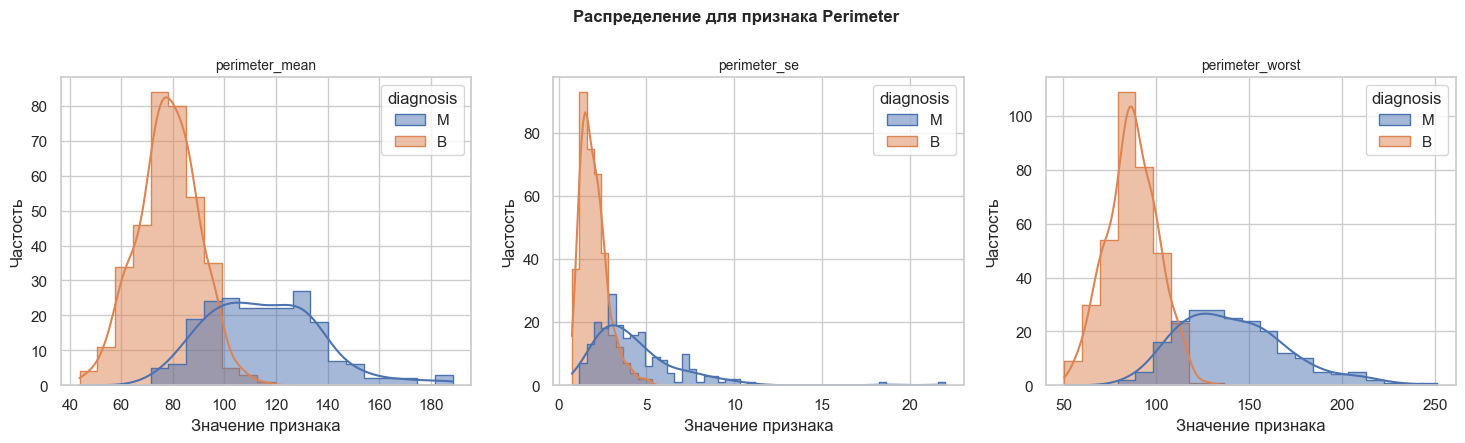

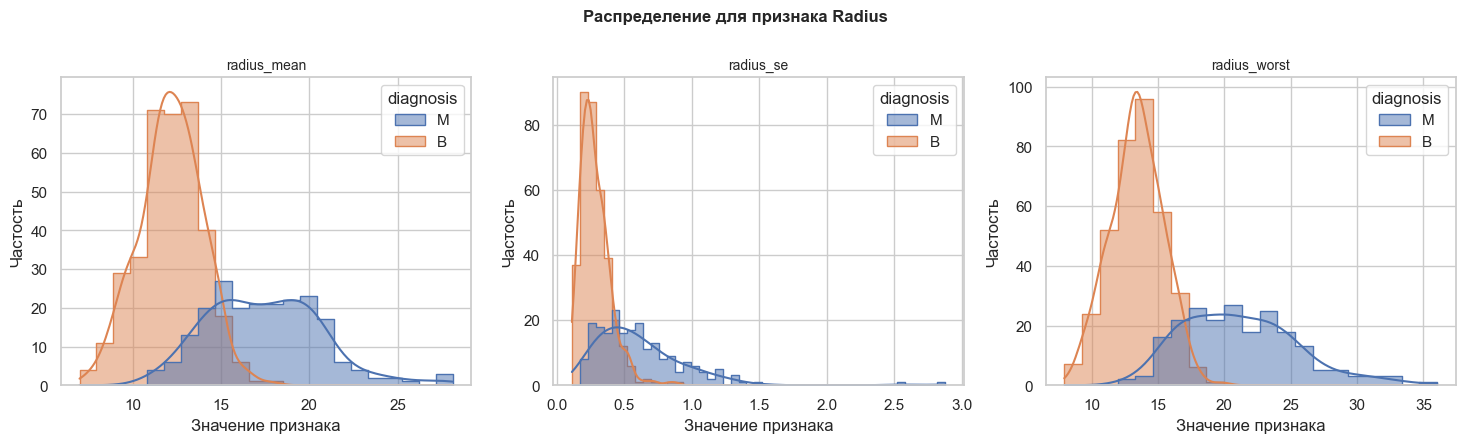

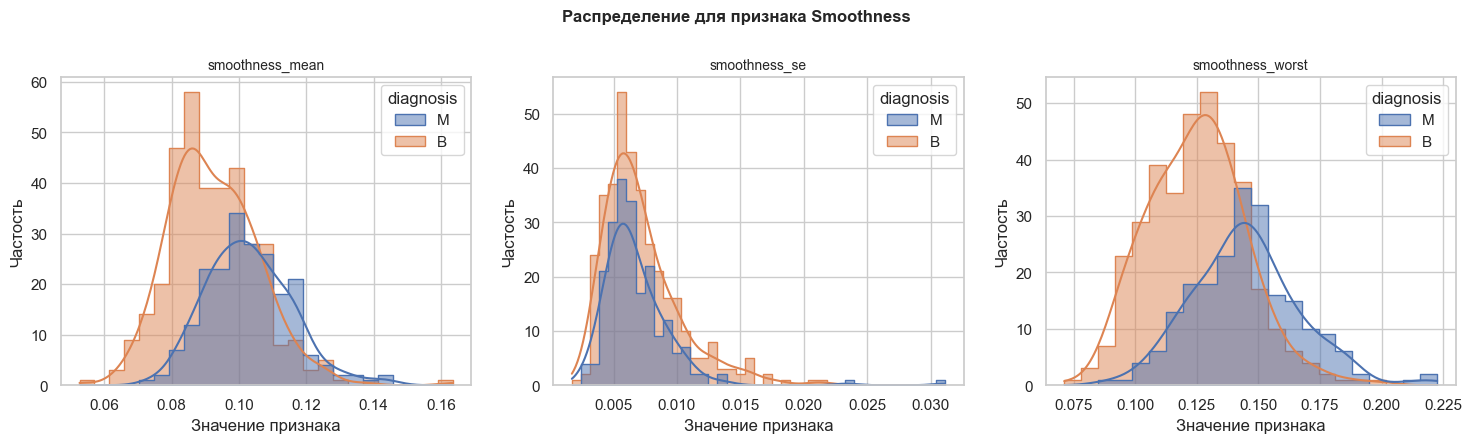

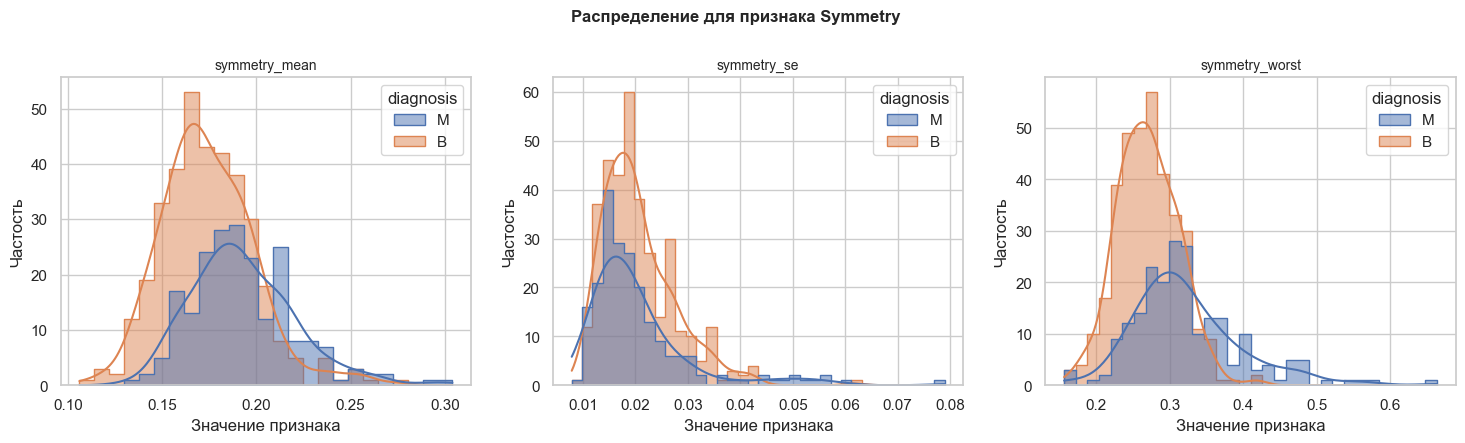

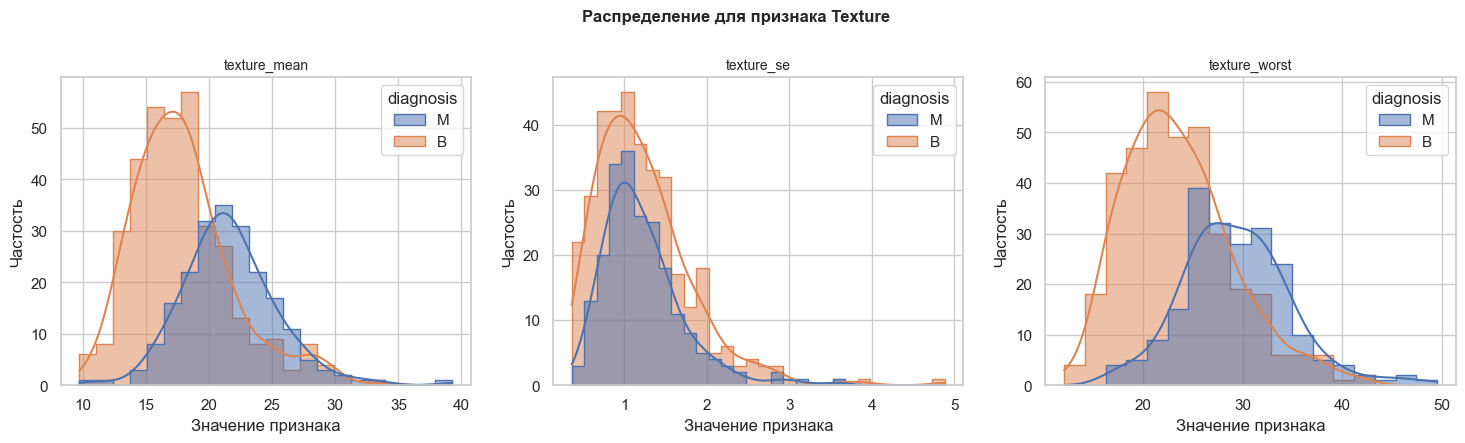

In [169]:
# Посмотрим, как распределение признаков выглядит на гистограммах.
# Находим базовые имена признаков (без суффиксов) и исключаем целевую переменную.
all_features = [col for col in df.columns if col not in ['diagnosis']]
base_features = sorted(list(set([col.split('_')[0] for col in all_features if '_' in col])))

# Строим графики: для каждого признака своя строка из 3 графиков (_mean, _se, _worst)
for base in base_features:
    fig, axes = plt.subplots(1, 3, figsize=(18, 4))
    fig.suptitle(f'Распределение для признака {base.capitalize()}', fontsize=12, fontweight='bold', y=1.05)
    
    suffixes = ['_mean', '_se', '_worst']
    
    for i, suffix in enumerate(suffixes):
        col_name = f'{base}{suffix}'
        
        if col_name in df.columns:
            sns.histplot(
                data=df, 
                x=col_name, 
                hue='diagnosis', 
                kde=True, 
                element='step',
                alpha=0.5, 
                ax=axes[i]
            )
            axes[i].set_title(f'{col_name}', fontsize=10)
            axes[i].set_xlabel('Значение признака')
            axes[i].set_ylabel('Частость')

#### Краткий анализ гистограмм.  
#### Общие положения:
* **_mean (Среднее значение)**: Показывает «базовый уровень» признака для всей опухоли. Чем сильнее разнесены графики по B и M, тем лучше для обучения модели. 
* **_se (Standard Error / Стандартная ошибка)**: Отражает неоднородность и хаотичность структуры.
* **_worst (Наихудшее/наибольшее значение)**: Среднее значение из трёх самых больших измерений.  
##### Для удобства интерпретации выделим логические группы:  
1. **Геометрические размеры (radius, perimeter, area)**  
   **_mean:** На всех графиках распределения смещены относительно друг друга. У злокачественных опухолей (M) **радиус**, **периметр** и **площадь** существенно выше, чем у доброкачественных (B).  
   **_se:** У злокачественных опухолей стандартная ошибка геометрических факторов выше.   
   **_worst:** Здесь разделение классов видно хорошо. 
2. **Текстура (texture)**  
   **_mean** и **_worst**: Графики довольно сильно пересекаются, но в комбинации с размерами, скорее всего, будет полезна.  
   **_se:** Разделение полностью отсутствует. Вероятно, признак будет мешать.
3. **Форма и контуры (concavity, concave points, compactness)**  
   **_mean** и **_worst**: Разделение по признакам достаточно хорошее, для обучения модели будут полезны.  
   **_se:** Разделение полностью отсутствует. Вероятно, признак будет мешать.  
4. **Внутренняя структура и микродетали (smoothness, symmetry, fractal_dimension)**  
   **_mean**, **_worst** и **_se:** Сильное прекрытие по всем признакам, особенно fractal_dimension. Надо проверять значимость признаков для модели.

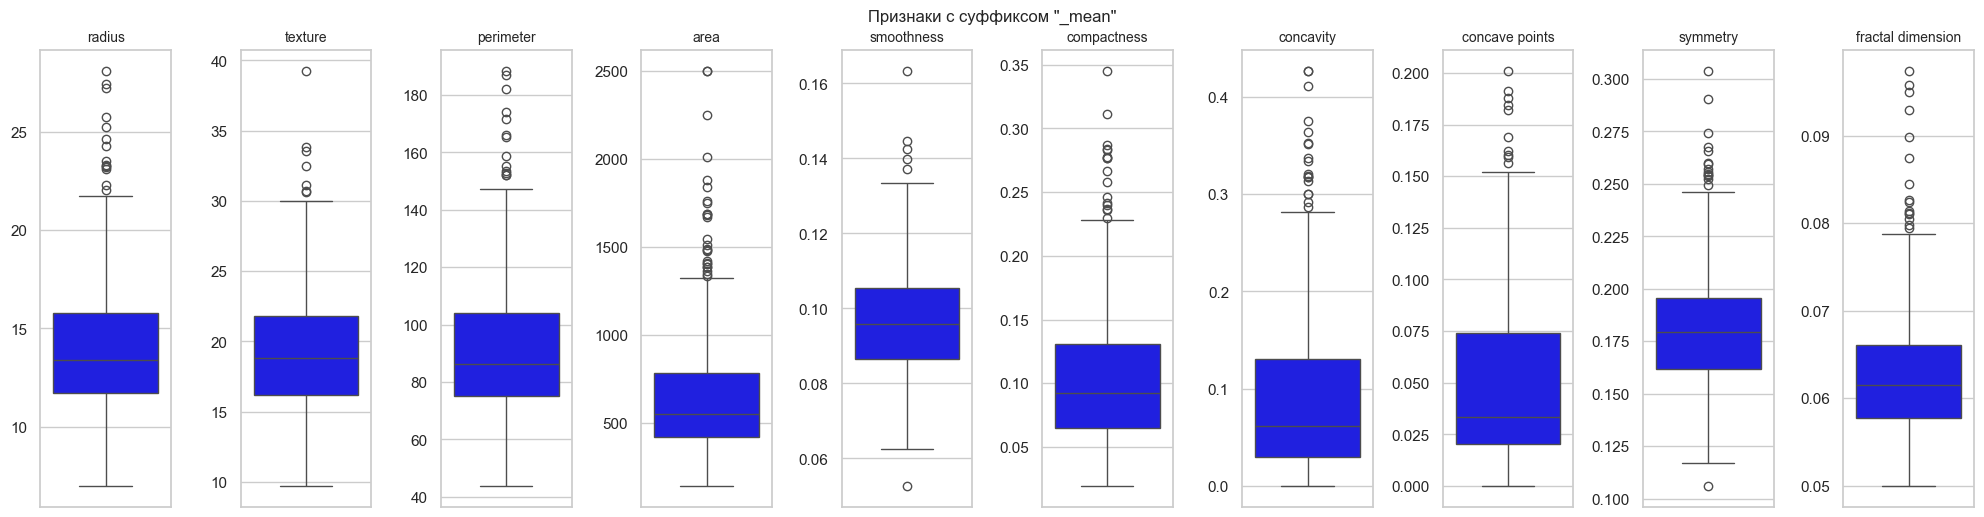

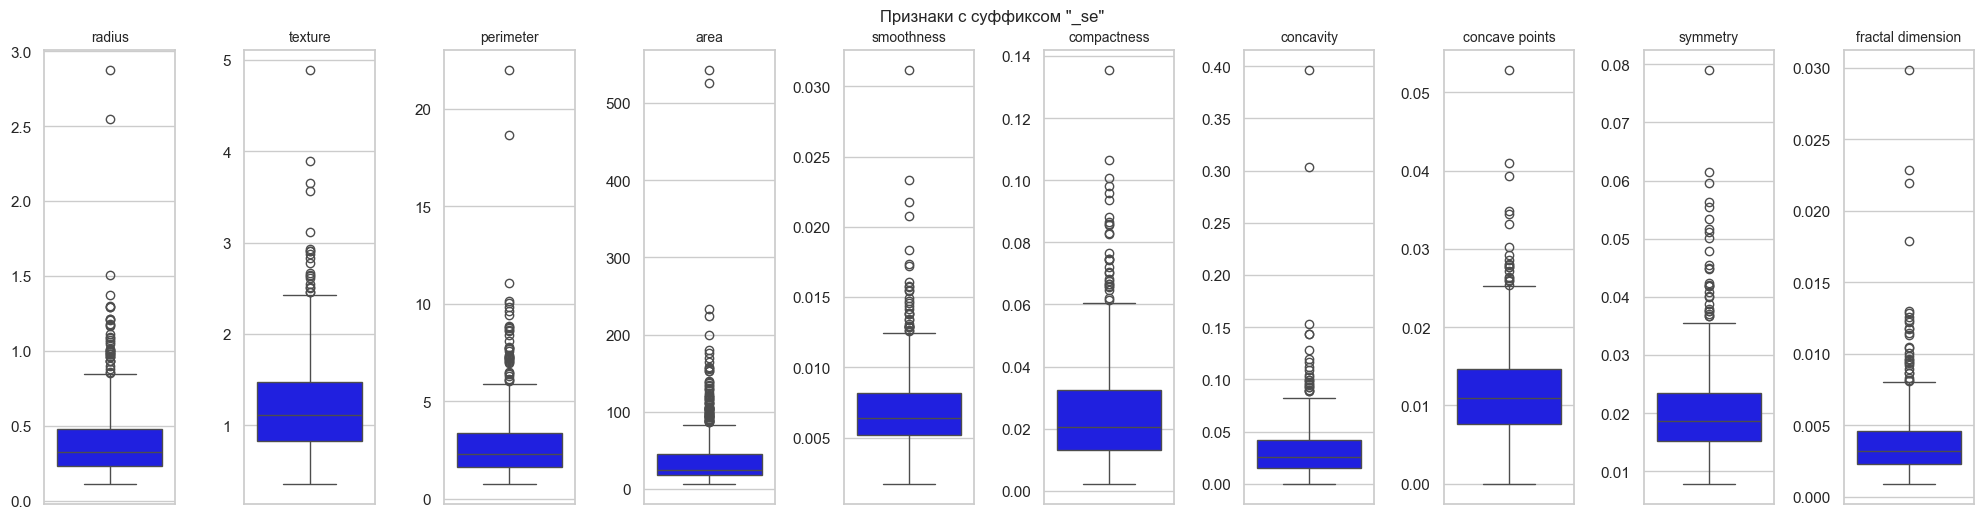

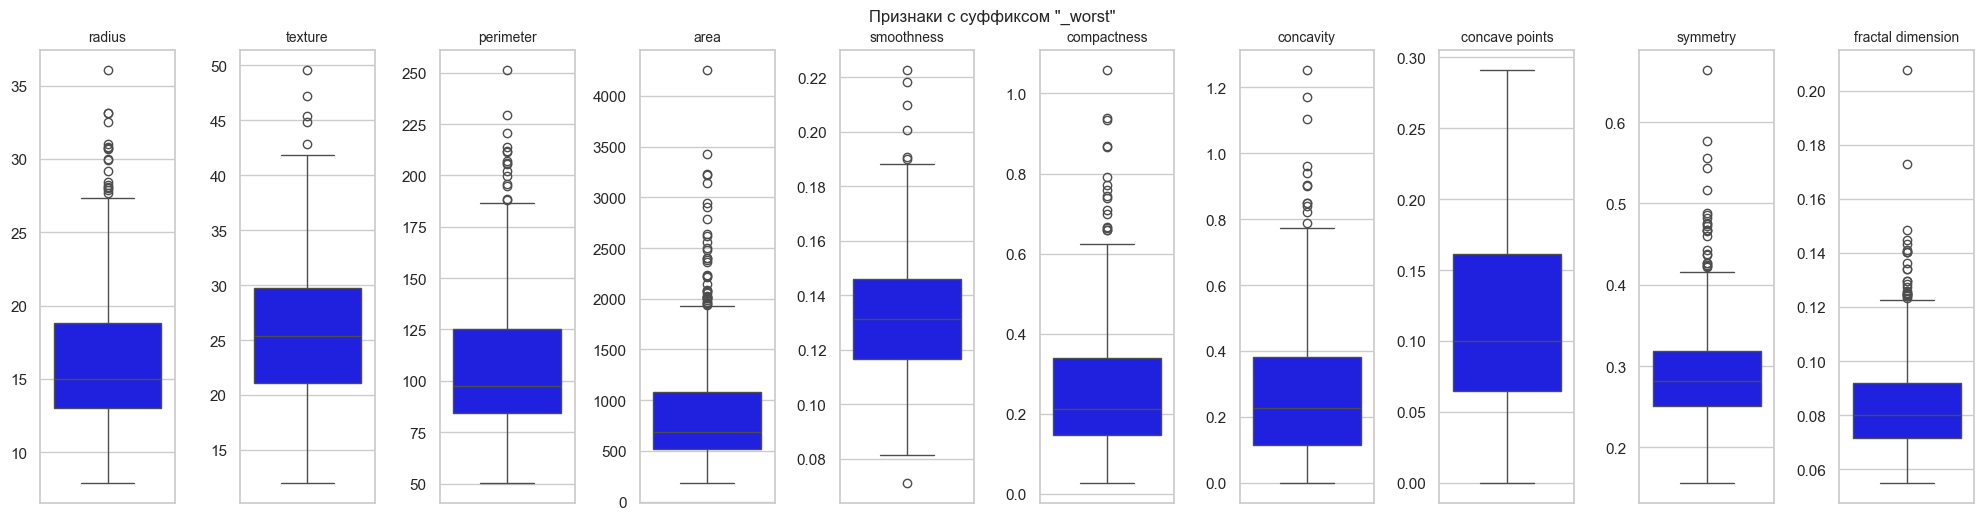

In [170]:
# Построим ящики с усами, чтобы посмотреть на характер распределения признаков.
# Отделяем целевую переменную
target_col = 'diagnosis'
feature_cols = [_c for _c in df.columns if _c != target_col]

# Группируем признаки по суффиксу
suffixes = ['_mean', '_se', '_worst']

groups = {}
for suff in suffixes:
    cols = [_c for _c in feature_cols if _c.endswith(suff)]
    if cols:
        groups[suff] = cols

for suff, cols in groups.items():
    base_names = [c[:-len(suff)] for c in cols]
    n = len(cols)
    ncols = 10
    nrows = 3

    fig, axes = plt.subplots(nrows, ncols, figsize=(20, 15))
    axes = axes.flatten()

    for ax, col, base in zip(axes, cols, base_names):
        sns.boxplot(y=df[col], ax=ax, color='blue')
        ax.set_title(base, fontsize=10)   # подпись сверху названием признака
        ax.set_ylabel('')
        ax.set_xlabel('')

    # Прячем пустые оси
    for ax in axes[n:]:
        ax.set_visible(False)

    fig.suptitle(f'Признаки с суффиксом "{suff}"', fontsize=12)
    fig.tight_layout(rect=[0, 0, 1, 1])
    plt.show()

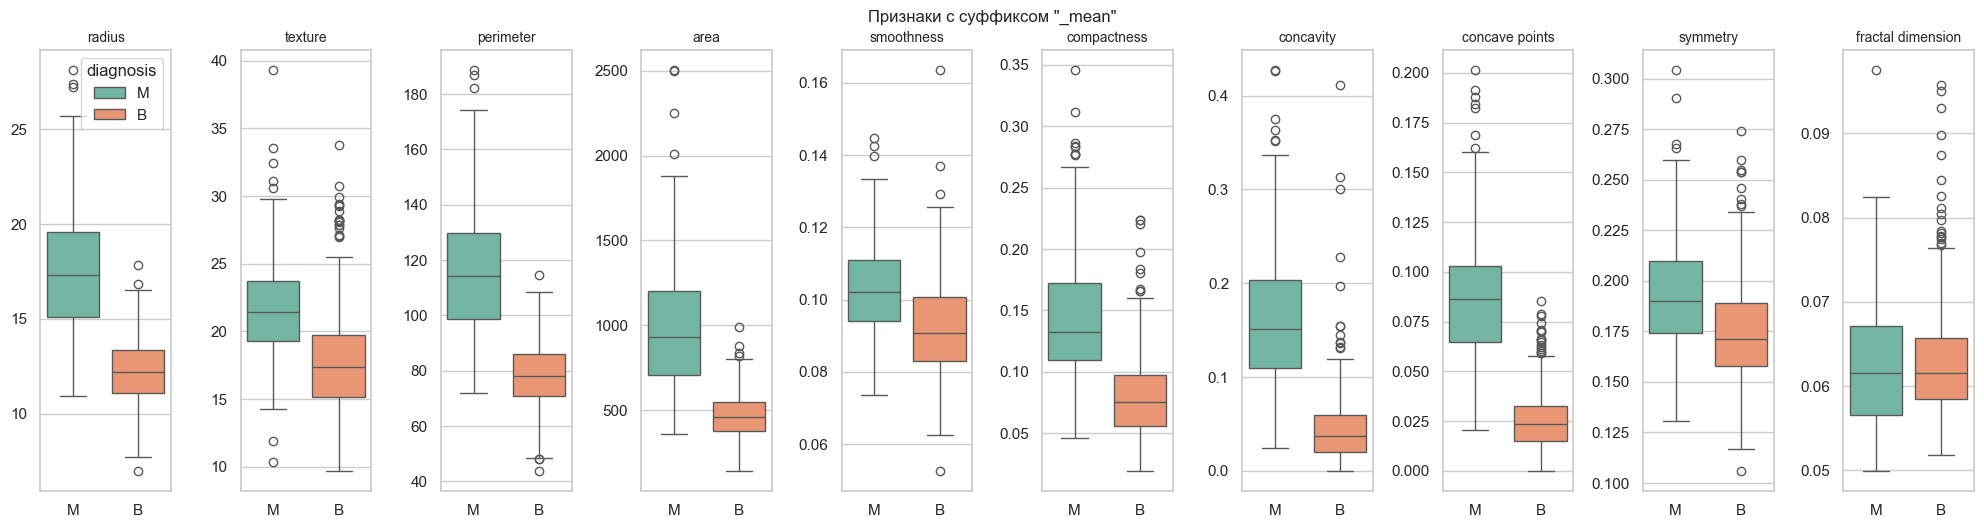

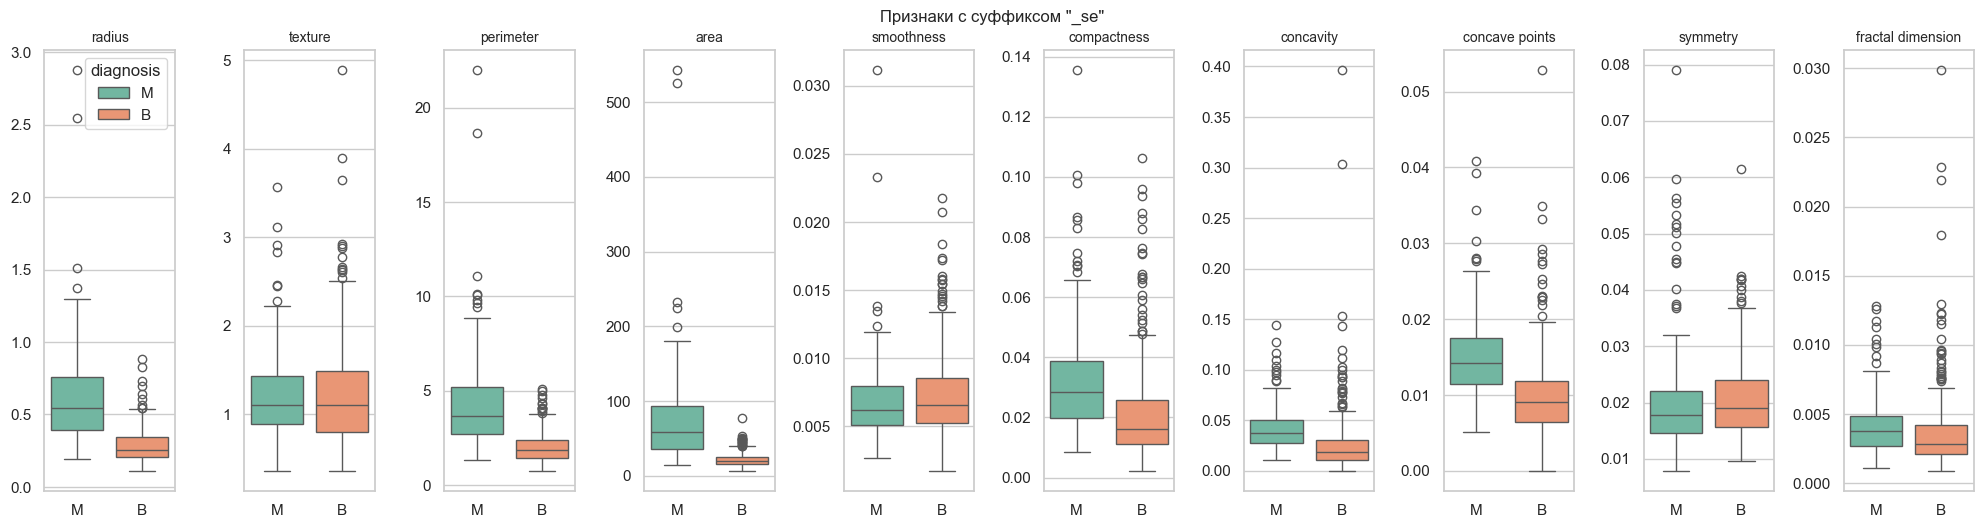

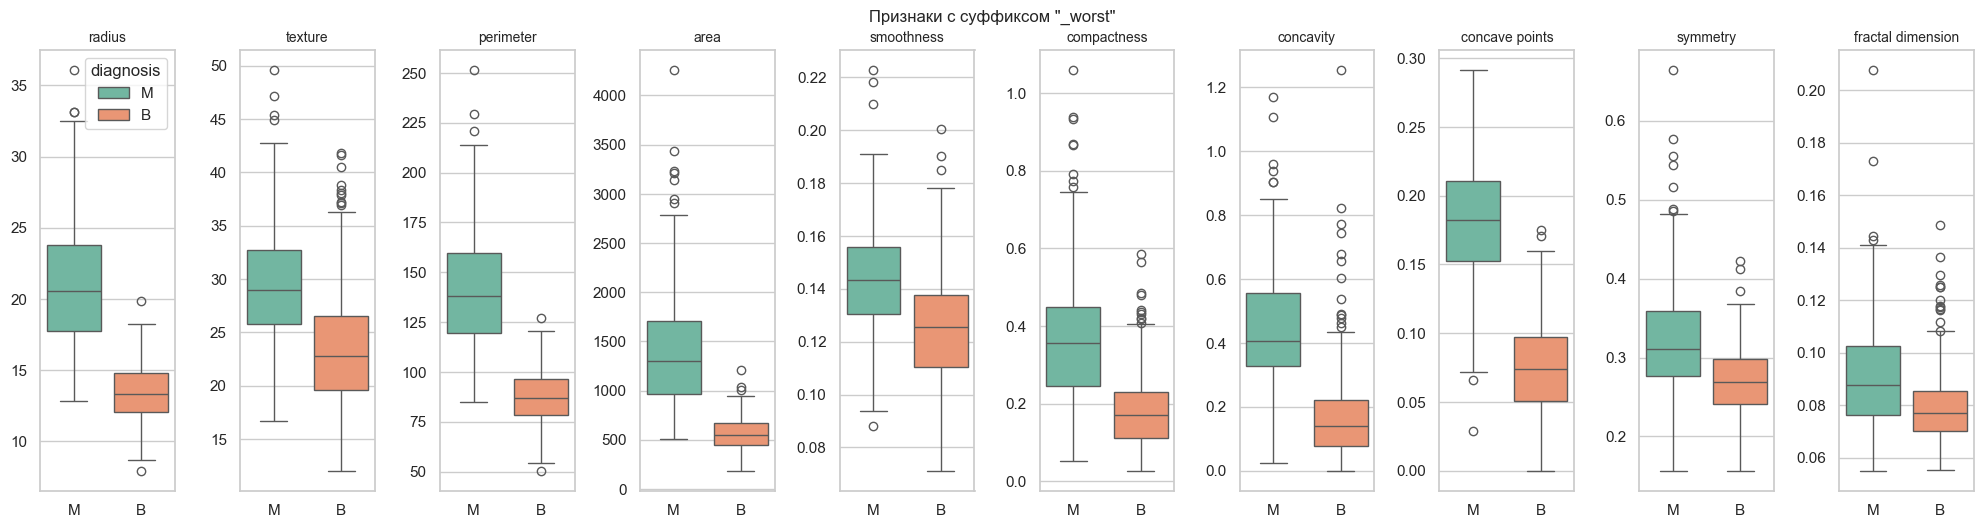

In [171]:
# Дополним графики разделением по целевой переменной
target_col = 'diagnosis'
feature_cols = [_c for _c in df.columns if _c != target_col]

# Группируем признаки по суффиксу
suffixes = ['_mean', '_se', '_worst']

groups = {}
for suff in suffixes:
    cols = [_c for _c in feature_cols if _c.endswith(suff)]
    if cols:
        groups[suff] = cols

for suff, cols in groups.items():
    base_names = [c[:-len(suff)] for c in cols]
    n = len(cols)
    ncols = 10
    nrows = 3

    fig, axes = plt.subplots(nrows, ncols, figsize=(20, 15))
    axes = axes.flatten()

    for i, (ax, col, base) in enumerate(zip(axes, cols, base_names)):
        sns.boxplot(
            data=df,
            y=col,
            x=target_col,
            hue=target_col,
            ax=ax,
            palette='Set2',
            legend=(i == 0)  # легенда только на первой оси, чтобы не дублировать
        )
        ax.set_title(base, fontsize=10)   # подпись сверху названием признака
        ax.set_ylabel('')
        ax.set_xlabel('')

    # Прячем пустые оси
    for ax in axes[n:]:
        ax.set_visible(False)

    fig.suptitle(f'Признаки с суффиксом "{suff}"', fontsize=12)
    fig.tight_layout(rect=[0, 0, 1, 1])
    plt.show()

#### Краткий анализ ящиков с усами.  
* Все признаки имеют выбросы. При их нормализации могут быть проблемы.

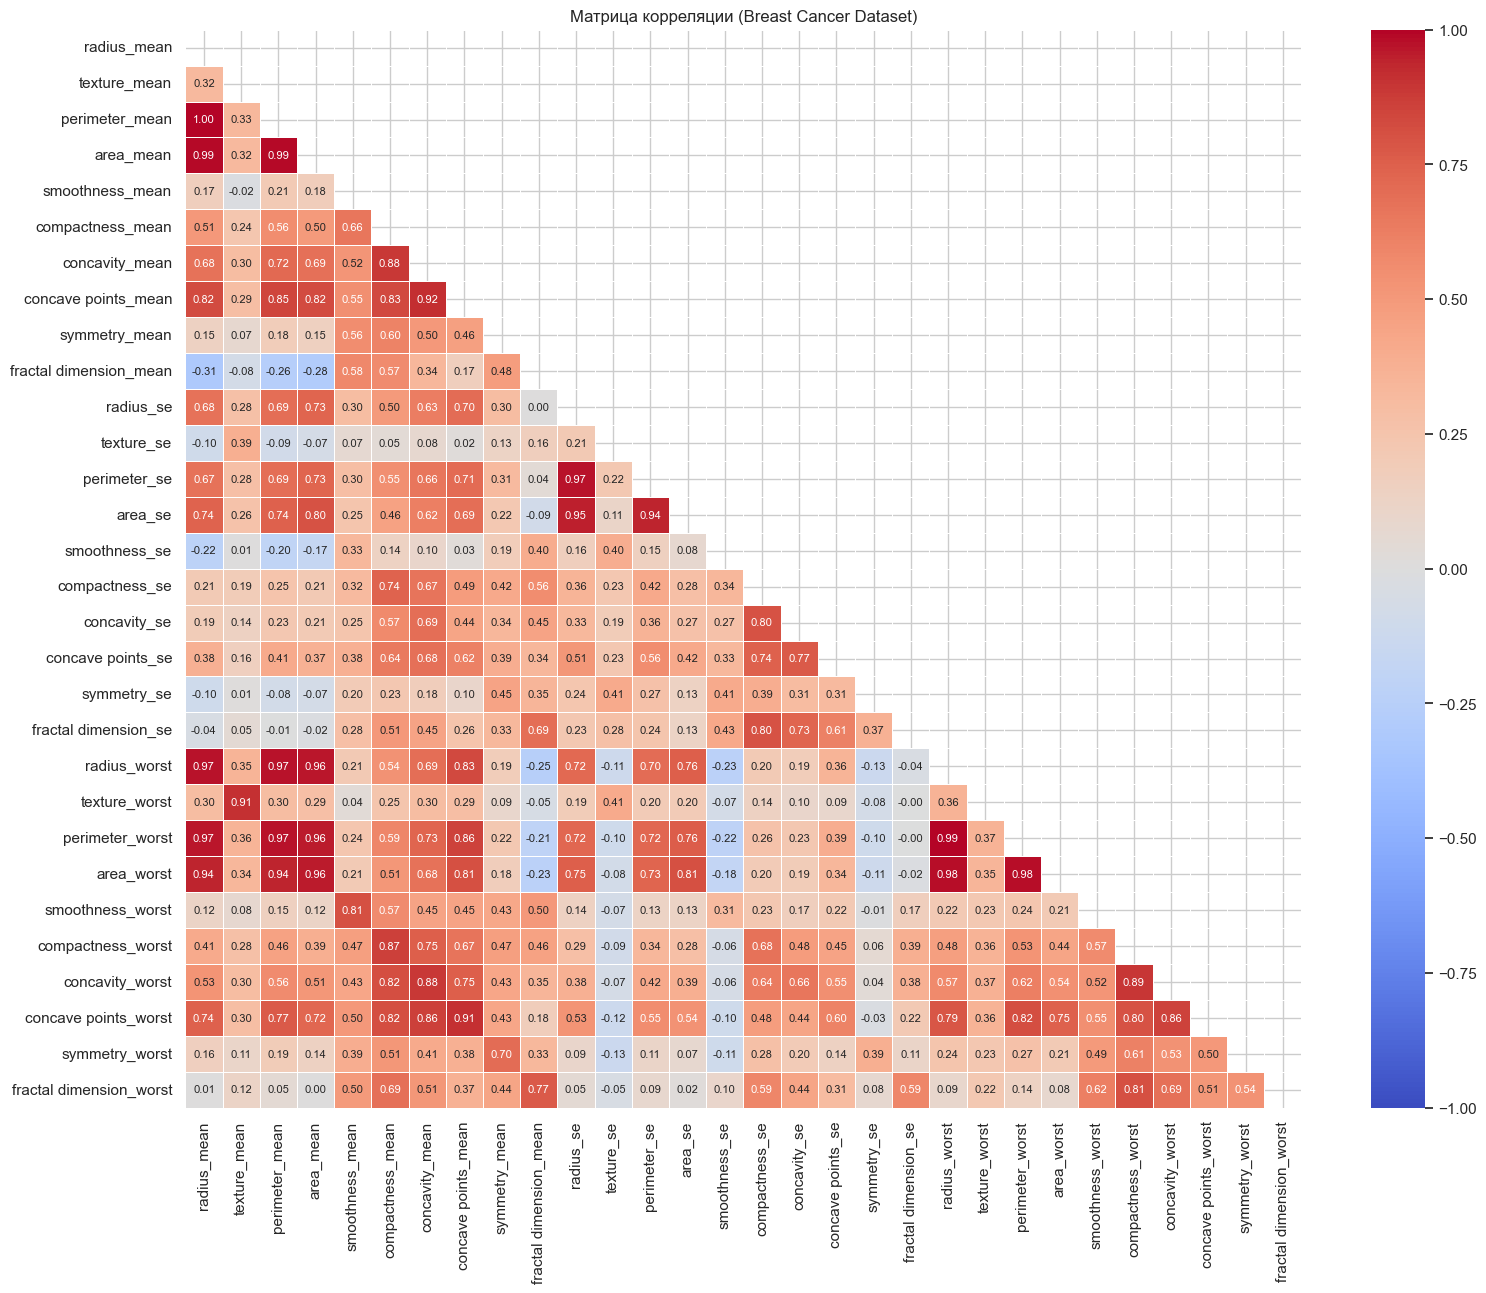

In [172]:
# Считаем матрицу корреляции
corr_matrix = df.corr(numeric_only=True)

# Создаем маску для верхней половины матрицы (включая главную диагональ)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(18, 14))

# Строим heatmap
sns.heatmap(
    corr_matrix,
    mask=mask,
    cmap="coolwarm",
    vmax=1,
    vmin=-1,
    annot=True,
    annot_kws={"size": 8},
    fmt=".2f",
    linewidths=0.5,
)

plt.title("Матрица корреляции (Breast Cancer Dataset)", fontsize=12)
plt.show()

In [173]:
# Посмотрим, сколько признаков сильно коррелируют
corr_matrix = df.corr(numeric_only=True)

# Берем только один треугольник (без диагонали), чтобы не дублировать пары
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Находим пары признаков с корреляцией больше 0.75
high_corr_pairs = []
for col in upper_tri.columns:
    correlated_with = upper_tri.index[upper_tri[col] > 0.75].tolist()
    for row in correlated_with:
        high_corr_pairs.append((row, col))

print(f"Найдено пар с корреляцией > 0.75: {len(high_corr_pairs)}")

Найдено пар с корреляцией > 0.75: 53


In [174]:
# 53 - очень много для построения графиков попарной корреляции. Посмотрим на пары с Ккор больше 0.85
corr_matrix = df.corr(numeric_only=True)

# Берем только один треугольник (без диагонали), чтобы не дублировать пары
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Находим пары признаков с корреляцией больше 0.85
high_corr_pairs = []
for col in upper_tri.columns:
    correlated_with = upper_tri.index[upper_tri[col] > 0.85].tolist()
    for row in correlated_with:
        high_corr_pairs.append((row, col))

print(f"Найдено пар с корреляцией > 0.85: {len(high_corr_pairs)}")

Найдено пар с корреляцией > 0.85: 29


In [175]:
# Посмотрим на список пар сильно коррелируемых признаков
high_corr_pairs.sort()
high_corr_pairs

[('area_mean', 'area_worst'),
 ('area_mean', 'perimeter_worst'),
 ('area_mean', 'radius_worst'),
 ('compactness_mean', 'compactness_worst'),
 ('compactness_mean', 'concavity_mean'),
 ('compactness_worst', 'concavity_worst'),
 ('concave points_mean', 'concave points_worst'),
 ('concave points_mean', 'perimeter_worst'),
 ('concavity_mean', 'concave points_mean'),
 ('concavity_mean', 'concave points_worst'),
 ('concavity_mean', 'concavity_worst'),
 ('concavity_worst', 'concave points_worst'),
 ('perimeter_mean', 'area_mean'),
 ('perimeter_mean', 'area_worst'),
 ('perimeter_mean', 'concave points_mean'),
 ('perimeter_mean', 'perimeter_worst'),
 ('perimeter_mean', 'radius_worst'),
 ('perimeter_se', 'area_se'),
 ('perimeter_worst', 'area_worst'),
 ('radius_mean', 'area_mean'),
 ('radius_mean', 'area_worst'),
 ('radius_mean', 'perimeter_mean'),
 ('radius_mean', 'perimeter_worst'),
 ('radius_mean', 'radius_worst'),
 ('radius_se', 'area_se'),
 ('radius_se', 'perimeter_se'),
 ('radius_worst', 'a

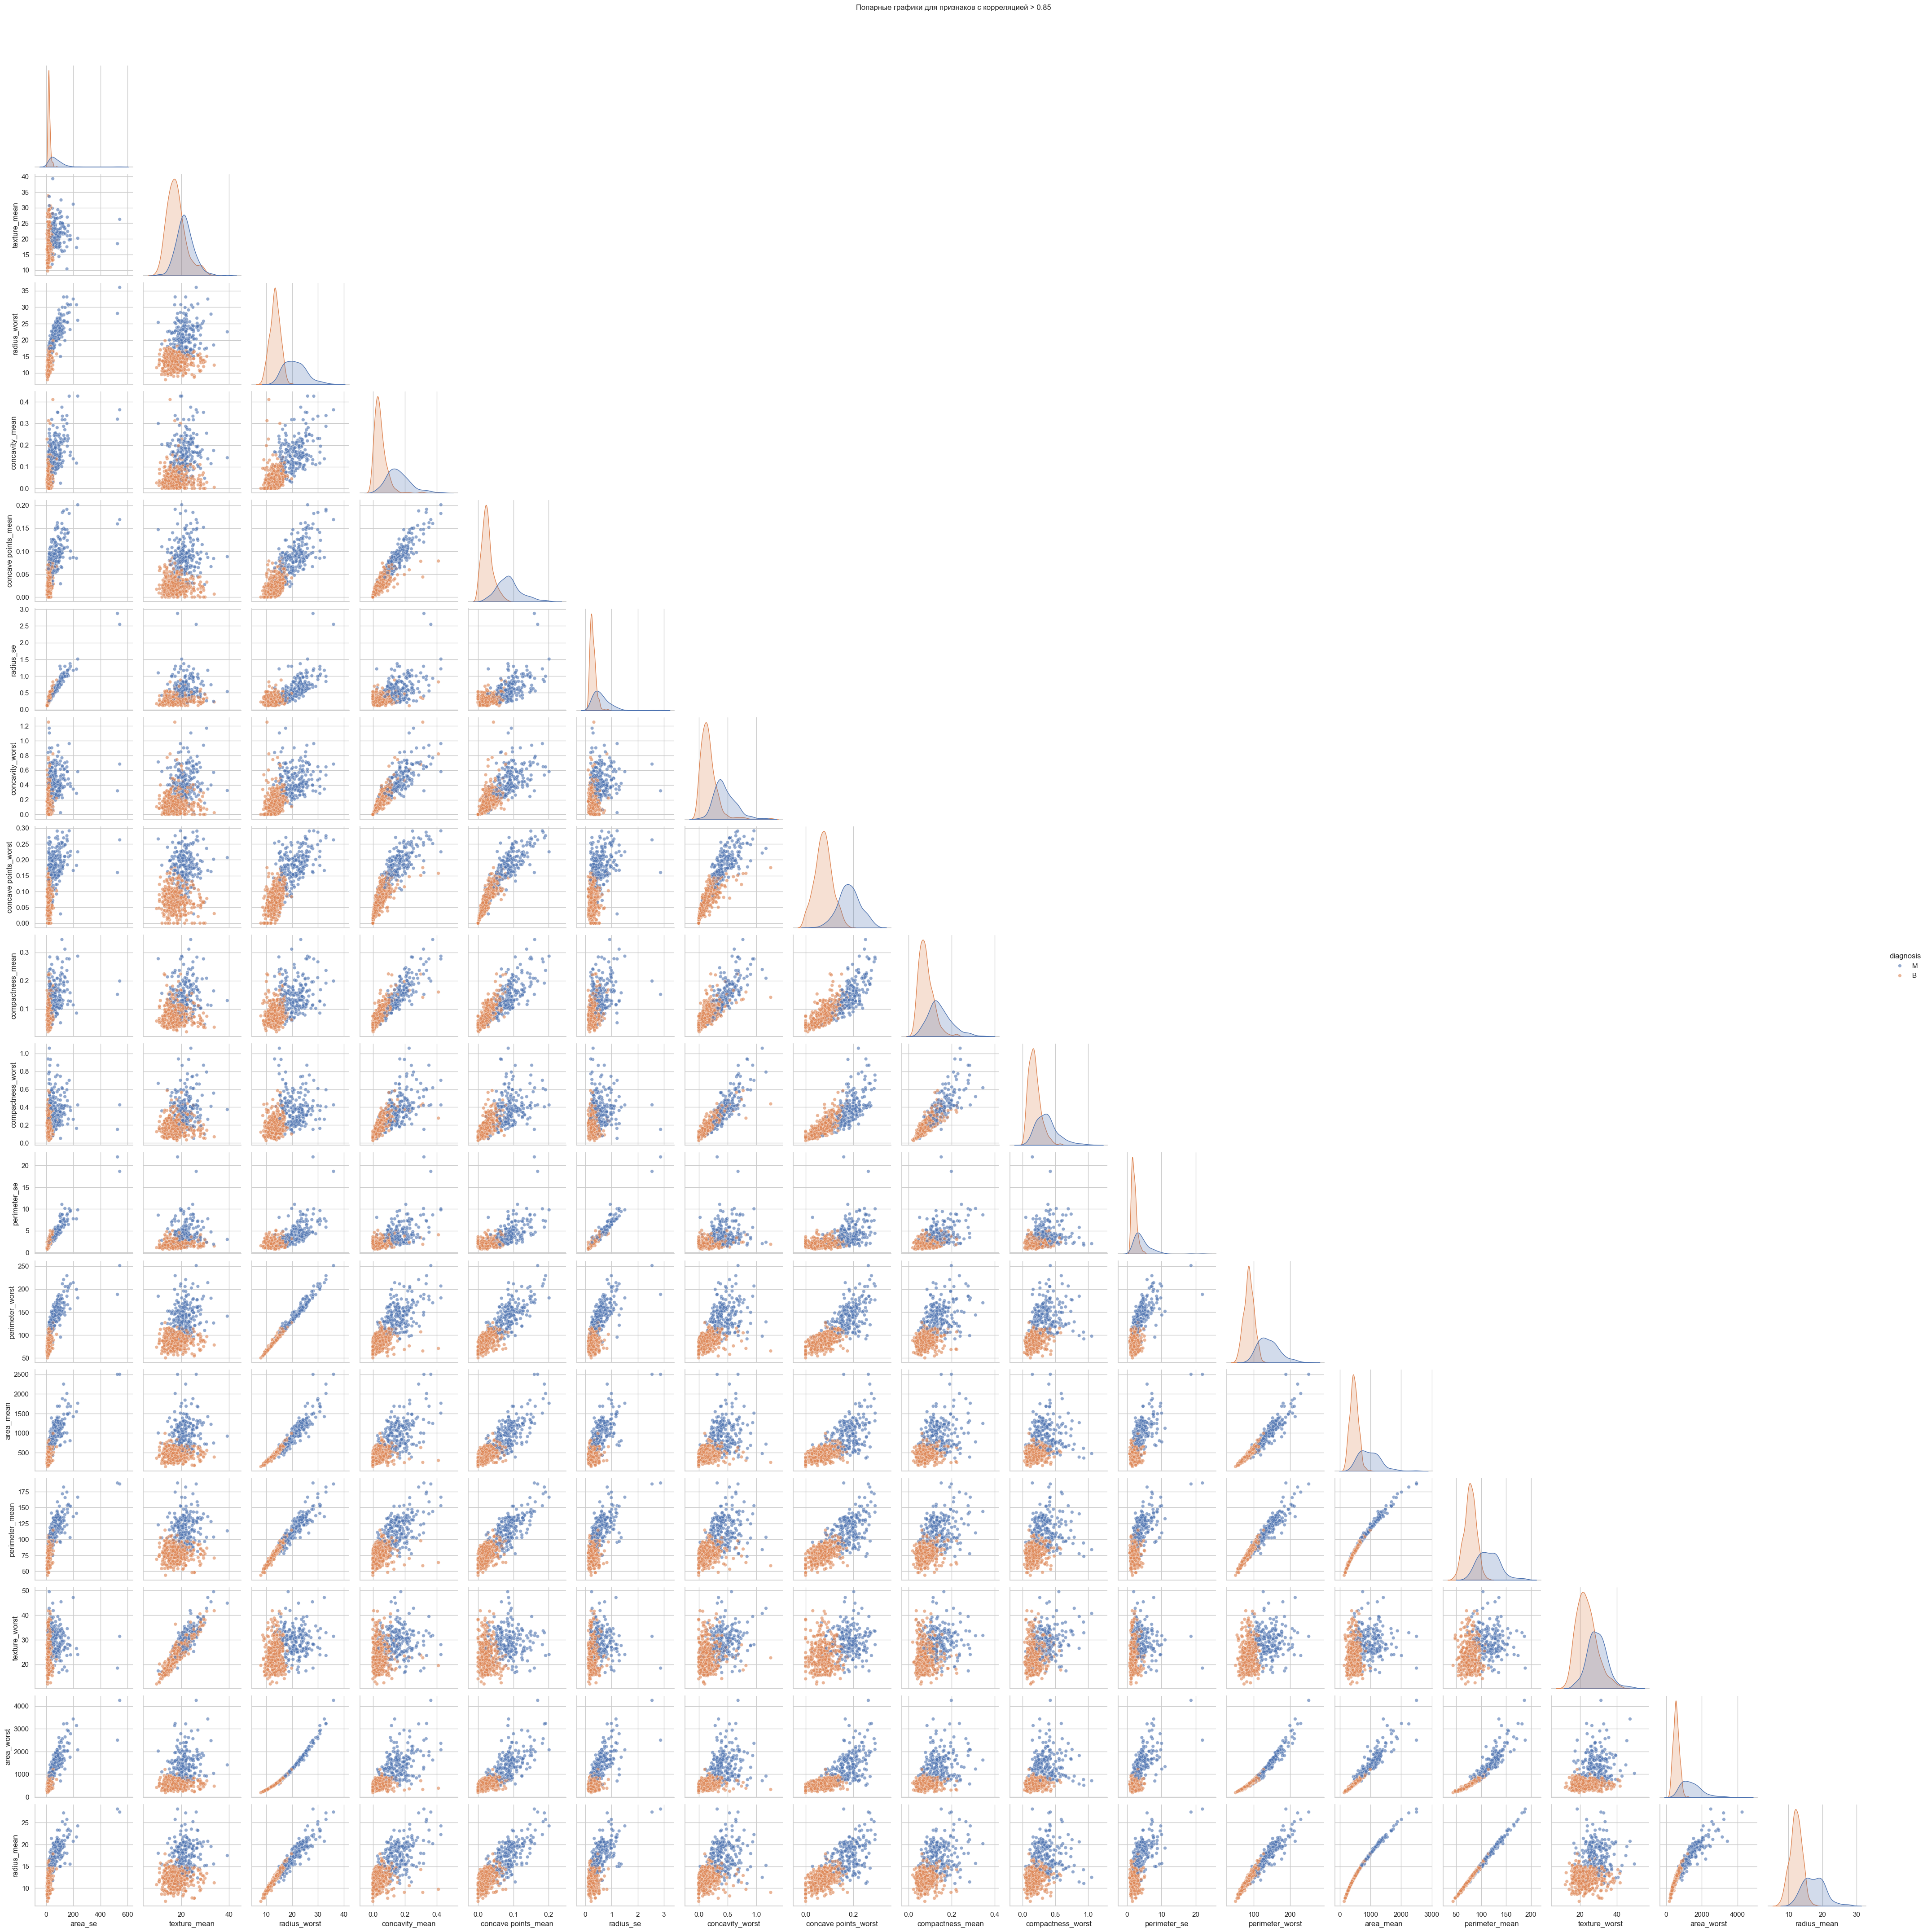

In [176]:
# 29 графиков можно построить. Получаем уникальный список всех признаков, которые участвуют в сильной корреляции
unique_features = list(
    set([item for pair in high_corr_pairs for item in pair])
)

# Строим попарные скаттерплоты
if unique_features:
    # Выделяем из исходного df только нужные признаки + колонку 'diagnosis' для цвета точек
    plot_df = df[unique_features].copy()
    if "diagnosis" in df.columns:
        plot_df["diagnosis"] = df["diagnosis"]

    # Строим pairplot
    sns.pairplot(
        plot_df,
        hue="diagnosis",
        kind="scatter",
        diag_kind="kde",
        corner=True,
        plot_kws={"alpha": 0.6, "s": 30},
    )
    plt.suptitle(
        "Попарные графики для признаков с корреляцией > 0.85", y=1.02, fontsize = 12,
    )
    plt.show()

In [177]:
# Разделим данные на train и test
from sklearn.model_selection import train_test_split

# Сначала кодитуем целевую пременную M - malignant -> 1, B - benign -> 0.
df['diagnosis'] = df['diagnosis'].map({'M': 1, 'B': 0})

# Выделяем признаки (X) и целевую переменную (y - столбец 'diagnosis'),
# который содержит метки классов (M - malignant (1), B - benign (0))
X = df.drop(columns=['diagnosis'])
y = df['diagnosis']

# Разделяем датасет в пропорции 70% / 30%. Т.к. есть дисбаланс классов, его надо сохранить.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.3,          # 30% данных уходит в тест
    stratify=y,             # сохраняем пропорции классов
    random_state=1101       # фиксируем сид для воспроизводимости результатов
)

# Проверяем размеры полученных выборок
print(f"Размер трейна: {X_train.shape}, Размер теста: {X_test.shape}")

print("\nДоля классов в исходном датасете:")
print(y.value_counts(normalize=True).round(3))

print("\nДоля классов в обучающей выборке (y_train):")
print(y_train.value_counts(normalize=True).round(3))

print("\nДоля классов в тестовой выборке (y_test):")
print(y_test.value_counts(normalize=True).round(3))

Размер трейна: (398, 30), Размер теста: (171, 30)

Доля классов в исходном датасете:
diagnosis
0    0.627
1    0.373
Name: proportion, dtype: float64

Доля классов в обучающей выборке (y_train):
diagnosis
0    0.628
1    0.372
Name: proportion, dtype: float64

Доля классов в тестовой выборке (y_test):
diagnosis
0    0.626
1    0.374
Name: proportion, dtype: float64


In [178]:
# Так как в данных много выбросов, МинМакс нормировка не подойдёт, попробуем 2 других варианта.

from sklearn.preprocessing import RobustScaler, StandardScaler

# Получаем 1-ый набор данных с нормировкой StandardScaler (приводит к mean=0, std=1)
std_scaler = StandardScaler()

# Обучаем только на трейне, трансформируем оба
X_train_std = std_scaler.fit_transform(X_train)
X_test_std = std_scaler.transform(X_test)


# Получаем 2-ой набор данных с нормировкой RobustScaler (использует медиану и IQR, устойчив к выбросам)
robust_scaler = RobustScaler()

# Обучаем только на трейне, трансформируем оба
X_train_robust = robust_scaler.fit_transform(X_train)
X_test_robust = robust_scaler.transform(X_test)


# Проверяем тип и форму полученных данных
print(f"Форма StandardScaler трейна: {X_train_std.shape}")
print(f"Форма RobustScaler трейна: {X_train_robust.shape}")

Форма StandardScaler трейна: (398, 30)
Форма RobustScaler трейна: (398, 30)


In [179]:
# По обоим полученным наборам построим модели kNN без настройки параметров 
# с оценкой метрик accuracy, precision, recall, f1 и ROC-AUC

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Инициализируем модели kNN с параметрами по умолчанию
knn_std = KNeighborsClassifier()
knn_robust = KNeighborsClassifier()

# Обучение и предсказание для набора после StandardScaler
knn_std.fit(X_train_std, y_train)
y_pred_std = knn_std.predict(X_test_std)
y_prob_std = knn_std.predict_proba(X_test_std)[:, 1]

# Обучение и предсказание для набора после RobustScaler
knn_robust.fit(X_train_robust, y_train)
y_pred_robust = knn_robust.predict(X_test_robust)
y_prob_robust = knn_robust.predict_proba(X_test_robust)[:, 1]

# Функция для оценки всех метрик
def get_metrics(y_true, y_pred, y_prob):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-Score": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

# Собираем результаты в один DataFrame для наглядности
results = pd.DataFrame({
    "StandardScaler + KNN": get_metrics(y_test, y_pred_std, y_prob_std),
    "RobustScaler + KNN": get_metrics(y_test, y_pred_robust, y_prob_robust)
}).round(4)

# Выводим таблицу результатов
print(results)


           StandardScaler + KNN  RobustScaler + KNN
Accuracy                 0.9532              0.9649
Precision                1.0000              1.0000
Recall                   0.8750              0.9062
F1-Score                 0.9333              0.9508
ROC-AUC                  0.9980              0.9988


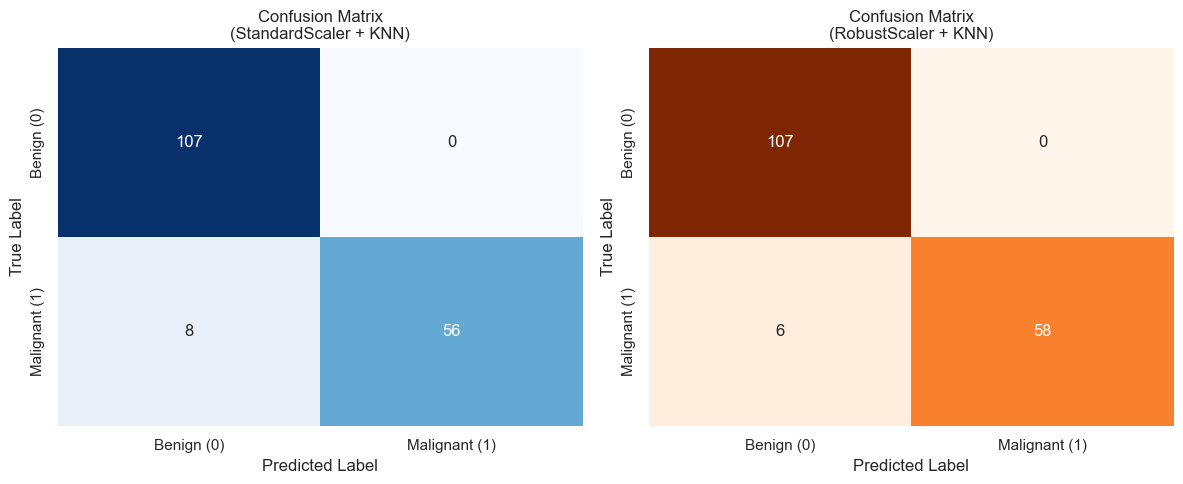

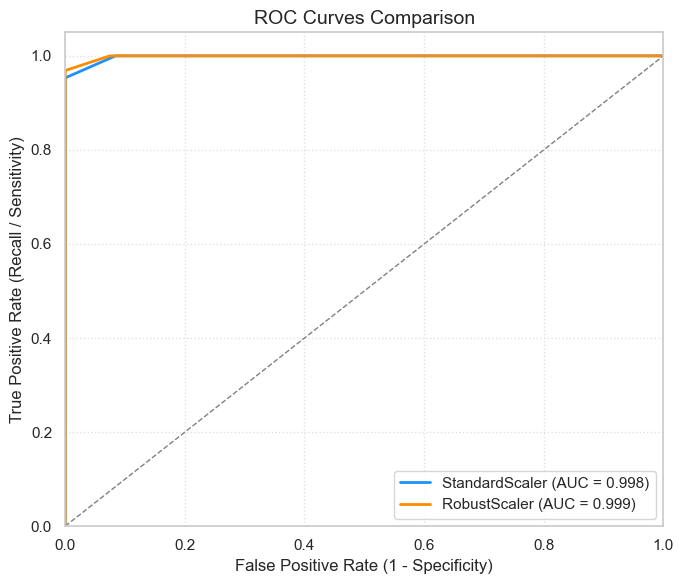

In [185]:
# Посмотрим графически на результаты:

from sklearn.metrics import confusion_matrix, roc_curve, auc

# График сравнения матриц ошибок
fig_cm, axes_cm = plt.subplots(1, 2, figsize=(12, 5))

# Матрица для StandardScaler
cm_std = confusion_matrix(y_test, y_pred_std)
sns.heatmap(cm_std, annot=True, fmt='d', cmap='Blues', ax=axes_cm[0], cbar=False,
            xticklabels=['Benign (0)', 'Malignant (1)'],
            yticklabels=['Benign (0)', 'Malignant (1)'])
axes_cm[0].set_title('Confusion Matrix\n(StandardScaler + KNN)', fontsize=12)
axes_cm[0].set_ylabel('True Label')
axes_cm[0].set_xlabel('Predicted Label')

# Матрица для RobustScaler
cm_robust = confusion_matrix(y_test, y_pred_robust)
sns.heatmap(cm_robust, annot=True, fmt='d', cmap='Oranges', ax=axes_cm[1], cbar=False,
            xticklabels=['Benign (0)', 'Malignant (1)'],
            yticklabels=['Benign (0)', 'Malignant (1)'])
axes_cm[1].set_title('Confusion Matrix\n(RobustScaler + KNN)', fontsize=12)
axes_cm[1].set_ylabel('True Label')
axes_cm[1].set_xlabel('Predicted Label')

plt.tight_layout()
plt.show()

# График сравнения ROC-кривых
plt.figure(figsize=(7, 6))

# Расчет кривой для StandardScaler
fpr_std, tpr_std, _ = roc_curve(y_test, y_prob_std)
roc_auc_std = auc(fpr_std, tpr_std)
plt.plot(fpr_std, tpr_std, color='dodgerblue', lw=2, 
         label=f'StandardScaler (AUC = {roc_auc_std:.3f})')

# Расчет кривой для RobustScaler
fpr_robust, tpr_robust, _ = roc_curve(y_test, y_prob_robust)
roc_auc_robust = auc(fpr_robust, tpr_robust)
plt.plot(fpr_robust, tpr_robust, color='darkorange', lw=2, 
         label=f'RobustScaler (AUC = {roc_auc_robust:.3f})')

# Диагональная линия 0.5
plt.plot([0, 1], [0, 1], color='grey', lw=1, linestyle='--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Recall / Sensitivity)')
plt.title('ROC Curves Comparison', fontsize=14)
plt.legend(loc="lower right")
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


In [187]:
# Настроим число соседей в каждой из моделей методом кросс-валидации
from sklearn.model_selection import GridSearchCV

# Задаем сетку параметров (проверим нечётные числа соседей от 1 до 29)
param_grid = {'n_neighbors': list(range(1, 30, 2))}

# Настраиваем GridSearchCV для набора после StandardScaler
grid_std = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=param_grid,
    scoring='roc_auc',
    cv=5,
    n_jobs=-1
)
grid_std.fit(X_train_std, y_train)

# Настраиваем GridSearchCV для набора после RobustScaler
grid_robust = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=param_grid,
    scoring='roc_auc',
    cv=5,
    n_jobs=-1
)
grid_robust.fit(X_train_robust, y_train)

# Выводим лучшие параметры и результаты кросс-валидации
print("=== Результаты для StandardScaler ===")
print(f"Лучшее число соседей (k): {grid_std.best_params_['n_neighbors']}")
print(f"Лучший ROC-AUC на кросс-валидации: {grid_std.best_score_:.3f}")

print("\n=== Результаты для RobustScaler ===")
print(f"Лучшее число соседей (k): {grid_robust.best_params_['n_neighbors']}")
print(f"Лучший ROC-AUC на кросс-валидации: {grid_robust.best_score_:.3f}")


=== Результаты для StandardScaler ===
Лучшее число соседей (k): 9
Лучший ROC-AUC на кросс-валидации: 0.992

=== Результаты для RobustScaler ===
Лучшее число соседей (k): 19
Лучший ROC-AUC на кросс-валидации: 0.990


In [189]:
# Посмотрим метрики с лучшими параметрами.
# Извлекаем лучшие модели, уже обученные на всем тренировочном наборе
best_knn_std = grid_std.best_estimator_
best_knn_robust = grid_robust.best_estimator_

# --- Оценка модели на данных StandardScaler ---
y_pred_best_std = best_knn_std.predict(X_test_std)
y_prob_best_std = best_knn_std.predict_proba(X_test_std)[:, 1]

# --- Оценка модели на данных RobustScaler ---
y_pred_best_robust = best_knn_robust.predict(X_test_robust)
y_prob_best_robust = best_knn_robust.predict_proba(X_test_robust)[:, 1]

# Функция для расчета метрик
def get_metrics(y_true, y_pred, y_prob):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-Score": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

# Формируем финальный DataFrame с результатами
final_results = pd.DataFrame({
    f"Оптимальный KNN (k={grid_std.best_params_['n_neighbors']}) + StandardScaler": 
        get_metrics(y_test, y_pred_best_std, y_prob_best_std),
    f"Оптимальный KNN (k={grid_robust.best_params_['n_neighbors']}) + RobustScaler": 
        get_metrics(y_test, y_pred_best_robust, y_prob_best_robust)
}).round(3)

# Выводим таблицу результатов
print(final_results)


           Оптимальный KNN (k=9) + StandardScaler  \
Accuracy                                    0.947   
Precision                                   1.000   
Recall                                      0.859   
F1-Score                                    0.924   
ROC-AUC                                     0.998   

           Оптимальный KNN (k=19) + RobustScaler  
Accuracy                                   0.947  
Precision                                  1.000  
Recall                                     0.859  
F1-Score                                   0.924  
ROC-AUC                                    0.999  


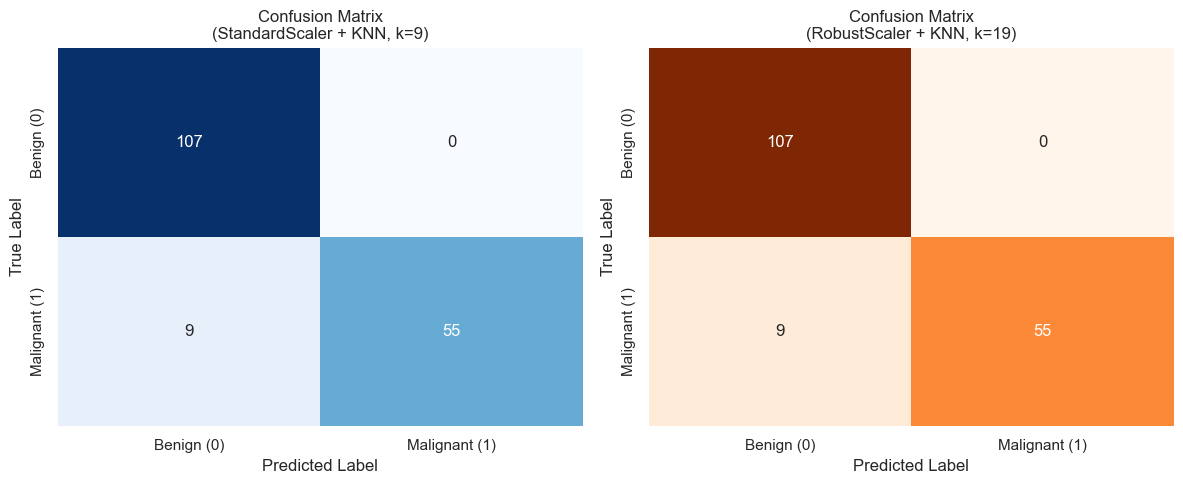

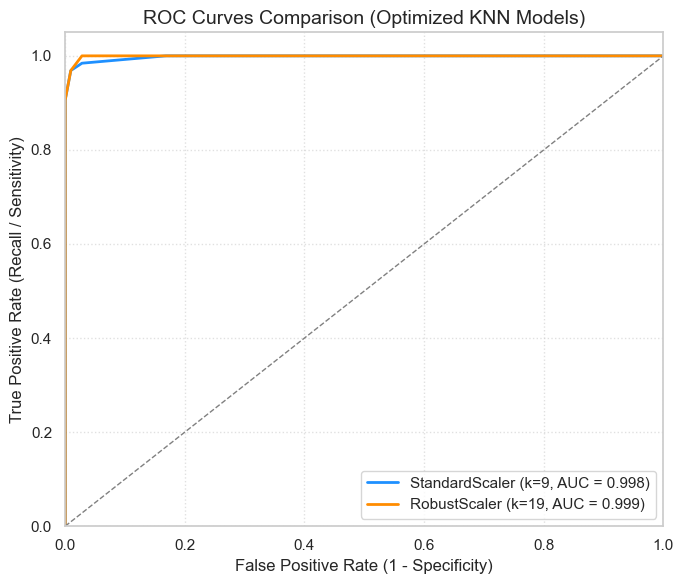

In [ ]:

# Посмотрим графически на результаты:
k_std = grid_std.best_params_['n_neighbors']
k_robust = grid_robust.best_params_['n_neighbors']

# График сравнения матриц ошибок
fig_cm, axes_cm = plt.subplots(1, 2, figsize=(12, 5))

# Матрица для StandardScaler + оптимальный KNN
cm_best_std = confusion_matrix(y_test, y_pred_best_std)
sns.heatmap(cm_best_std, annot=True, fmt='d', cmap='Blues', ax=axes_cm[0], cbar=False,
            xticklabels=['Benign (0)', 'Malignant (1)'],
            yticklabels=['Benign (0)', 'Malignant (1)'])
axes_cm[0].set_title(f'Confusion Matrix\n(StandardScaler + KNN, k={k_std})', fontsize=12)
axes_cm[0].set_ylabel('True Label')
axes_cm[0].set_xlabel('Predicted Label')

# Матрица для RobustScaler + оптимальный KNN
cm_best_robust = confusion_matrix(y_test, y_pred_best_robust)
sns.heatmap(cm_best_robust, annot=True, fmt='d', cmap='Oranges', ax=axes_cm[1], cbar=False,
            xticklabels=['Benign (0)', 'Malignant (1)'],
            yticklabels=['Benign (0)', 'Malignant (1)'])
axes_cm[1].set_title(f'Confusion Matrix\n(RobustScaler + KNN, k={k_robust})', fontsize=12)
axes_cm[1].set_ylabel('True Label')
axes_cm[1].set_xlabel('Predicted Label')

plt.tight_layout()
plt.show()

# График сравнения ROC-кривых (Оптимальные модели)
plt.figure(figsize=(7, 6))

# Расчет кривой для оптимального StandardScaler
fpr_best_std, tpr_best_std, _ = roc_curve(y_test, y_prob_best_std)
roc_auc_best_std = auc(fpr_best_std, tpr_best_std)
plt.plot(fpr_best_std, tpr_best_std, color='dodgerblue', lw=2, 
         label=f'StandardScaler (k={k_std}, AUC = {roc_auc_best_std:.3f})')

# Расчет кривой для оптимального RobustScaler
fpr_best_robust, tpr_best_robust, _ = roc_curve(y_test, y_prob_best_robust)
roc_auc_best_robust = auc(fpr_best_robust, tpr_best_robust)
plt.plot(fpr_best_robust, tpr_best_robust, color='darkorange', lw=2, 
         label=f'RobustScaler (k={k_robust}, AUC = {roc_auc_best_robust:.3f})')

# Диагональная линия 0.5
plt.plot([0, 1], [0, 1], color='grey', lw=1, linestyle='--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Recall / Sensitivity)')
plt.title('ROC Curves Comparison (Optimized KNN Models)', fontsize=14)
plt.legend(loc="lower right")
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


#### Краткий анализ результатов.  
* **kNN** из "коробки" показал лучшие результаты, чем после подбора гиперпараметра "число соседей".  
* Скорее всего, это связано с наличием большого колочества мультиколлинеарных данных. Необходимо выполнить либо отбраковку признаков, либо применить методы уменьшения размерности.